# Phase 6 : comportements transactionnels (Q2, Q6)

Ce notebook décrit les comportements des clients : montants, canaux de paiement, évolution dans le temps, lieux, catégories de commerçants, erreurs, puis comportements de chaque profil de la phase 5. Il part de la table d'analyse (P4-10). Les fonctions de comparaison sont dans `src/comparisons.py`. Chaque étape est expliquée dans `docs/`.

Avec 13 millions de lignes, presque tout écart est « significatif ». Chaque comparaison chiffrée donne donc aussi la taille de l'écart (P6-06).

## Chargement des données

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.load_data import load_clean_table
from src.charte import (
    apply_style, save_figure, CATEGORIES, BLUE, ORANGE, TEXT_SECONDARY, THOUSANDS, DECIMALS, sequential_cmap,
)
from src.comparisons import rate_table, chi2_test

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

colonnes = ["id", "date", "client_id", "card_id", "amount", "use_chip", "is_online", "is_foreign",
            "merchant_state_clean", "merchant_country", "mcc", "mcc_family", "has_error", "has_auth_error",
            "err_insufficient_balance", "err_technical_glitch", "err_bad_pin", "err_bad_cvv",
            "err_bad_card_number", "err_bad_expiration", "err_bad_zipcode", "year", "month", "weekday",
            "hour", "is_night", "is_weekend", "is_round_amount", "is_negative_amount", "is_zero_amount",
            "card_auth_errors_24h"]
df = load_clean_table("analysis", columns=colonnes)
df_mcc = load_clean_table("mcc")
achats = df["amount"] > 0
df["achat"] = df["amount"].where(achats, 0.0)
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
CANAUX = {"Swipe Transaction": "Bande magnétique", "Chip Transaction": "Puce", "Online Transaction": "En ligne"}
df["canal"] = df["use_chip"].map(CANAUX).astype("category")
print(f"{len(df):,} transactions chargées")

13,305,915 transactions chargées


## P6-01 : analyser les montants

Distribution, médiane et valeurs extrêmes des achats (montants positifs), puis montants ronds et remboursements (montants négatifs).

Critère de fin : graphiques et constats chiffrés. Voir `docs/P6-01_montants.md`.

In [2]:
montants_achats = df.loc[achats, "amount"]
remboursements = df.loc[df["amount"] < 0, "amount"]
print(f"Achats : {len(montants_achats):,} ; remboursements : {len(remboursements):,} ; "
      f"montants nuls : {int(df['is_zero_amount'].sum()):,}")
print(f"Achats : médiane {montants_achats.median():.2f} $, moyenne {montants_achats.mean():.2f} $")
print(f"Achats : quantile 1 % {montants_achats.quantile(0.01):.2f} $, 99 % {montants_achats.quantile(0.99):.2f} $, "
      f"99,9 % {montants_achats.quantile(0.999):.2f} $, maximum {montants_achats.max():.2f} $")
print(f"Achats de plus de 1 000 $ : {int((montants_achats > 1000).sum()):,}")
print(f"Remboursements : médiane {remboursements.median():.2f} $, total {remboursements.sum():,.0f} $")
print(f"Total des achats : {montants_achats.sum():,.0f} $")

Achats : 12,635,227 ; remboursements : 660,049 ; montants nuls : 10,639
Achats : médiane 31.92 $, moyenne 50.60 $
Achats : quantile 1 % 0.63 $, 99 % 324.52 $, 99,9 % 906.87 $, maximum 6820.20 $
Achats de plus de 1 000 $ : 9,185
Remboursements : médiane -79.00 $, total -67,519,042 $
Total des achats : 639,354,565 $


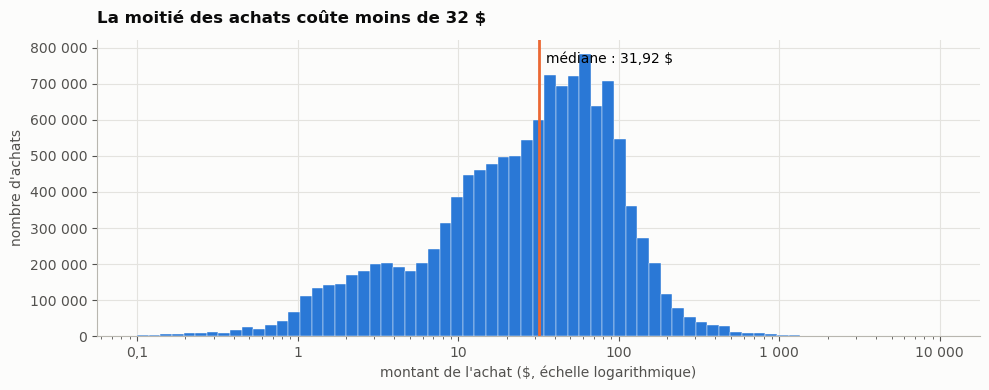

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(-1, 4, 70)
ax.hist(montants_achats, bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
mediane = montants_achats.median()
ax.axvline(mediane, color=ORANGE, linewidth=2)
ax.text(mediane * 1.1, ax.get_ylim()[1] * 0.92, f"médiane : {mediane:.2f} $".replace(".", ","), color="black")
ax.set_xlabel("montant de l'achat ($, échelle logarithmique)")
ax.set_ylabel("nombre d'achats")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000])
ax.set_xticklabels(["0,1", "1", "10", "100", "1 000", "10 000"])
ax.set_title('La moitié des achats coûte moins de 32 $')
fig.tight_layout()
save_figure(fig, "P6-01_montants")
plt.show()

In [4]:
part = pd.DataFrame({
    "remboursements_%": rate_table(df, "mcc_family", "is_negative_amount")["taux_%"],
    "achats_sans_centimes_%": rate_table(df, "mcc_family", "is_round_amount")["taux_%"],
}).sort_values("remboursements_%", ascending=False)
print(f"Part des remboursements : {100 * df['is_negative_amount'].mean():.2f} % ; "
      f"part des achats sans centimes : {100 * df['is_round_amount'].mean():.2f} %")
part.round(2)

Part des remboursements : 4.96 % ; part des achats sans centimes : 10.15 %


,remboursements_%,achats_sans_centimes_%
mcc_family,,
Industrie et fabrication,28.36,28.83
Voyage et hébergement,27.45,27.92
Alimentation,9.13,9.92
"Transport, carburant et automobile",9.03,9.85
"Maison, jardin et électronique",1.42,2.41
Services publics et télécommunications,0.73,1.70
"Vêtements, beauté et services personnels",0.00,1.02
Grandes surfaces et commerces divers,0.00,0.99
Santé et soins,0.00,0.98


**Constats**

- Sur 13 305 915 transactions : 12 635 227 achats (montant positif), 660 049 remboursements (montant négatif) et 10 639 montants nuls.
- La moitié des achats coûte moins de 31,92 $. La moyenne (50,60 $) est plus haute que la médiane : quelques gros achats tirent la moyenne vers le haut.
- 1 % des achats coûte moins de 0,63 $ et 1 % plus de 324,52 $. Le quantile 99,9 % vaut 906,87 $ et le maximum 6 820,20 $. 9 185 achats dépassent 1 000 $.
- Le graphique montre que la plupart des achats se situent entre 10 et 100 $, avec un second groupe plus petit de quelques dollars.
- Les achats totalisent 639 354 565 $ et les remboursements -67 519 042 $ (remboursement médian : -79,00 $).
- Les remboursements (4,96 % des transactions) n'existent que dans six familles. Ils sont fréquents en industrie et fabrication (28,36 %) et en voyage et hébergement (27,45 %), et absents des six autres familles.
- Les achats sans centimes font 10,15 % des transactions, mais 80,57 % en services professionnels et financiers.

## P6-02 : analyser les canaux de paiement

Bande magnétique (Swipe), puce (Chip) et en ligne : répartition et évolution par année.

Critère de fin : graphique commenté. Voir `docs/P6-02_canaux_paiement.md`.

In [5]:
canaux = pd.crosstab(df["year"], df["canal"], normalize="index").mul(100)
canaux = canaux[["Bande magnétique", "Puce", "En ligne"]]
print(df["canal"].value_counts().to_string())
canaux.round(1)

Bande magnétique    6967185
Puce                4780818
En ligne            1557912


canal,Bande magnétique,Puce,En ligne
year,,,
2010,89.1,0.0,10.9
2011,89.2,0.0,10.8
2012,88.9,0.0,11.1
2013,88.4,0.0,11.6
2014,88.2,0.0,11.8
2015,16.9,70.8,12.2
2016,16.8,71.0,12.2
2017,16.8,71.2,12.1
2018,16.9,71.0,12.1


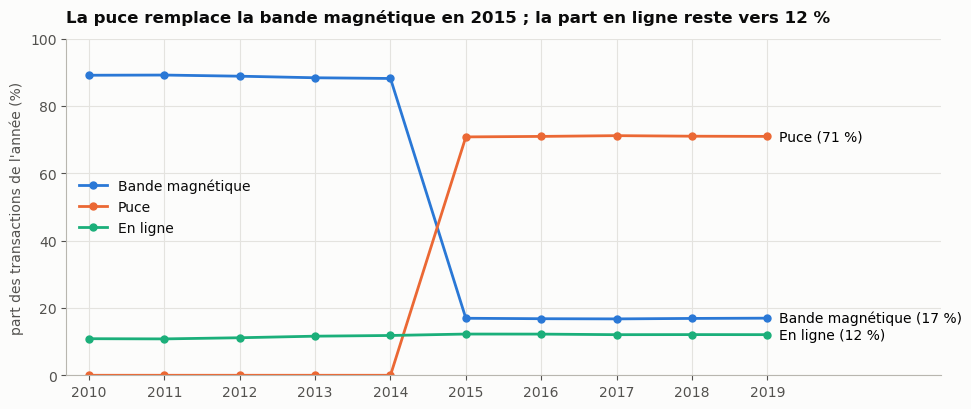

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for couleur, canal in zip(CATEGORIES, canaux.columns):
    ax.plot(canaux.index, canaux[canal], marker="o", markersize=5, color=couleur, label=canal)
    ax.text(canaux.index[-1] + 0.15, canaux[canal].iloc[-1], f"{canal} ({canaux[canal].iloc[-1]:.0f} %)",
            va="center", color="black")
ax.set_xticks(canaux.index)
ax.set_xlim(canaux.index[0] - 0.3, canaux.index[-1] + 2.3)
ax.set_ylim(0, 100)
ax.set_ylabel("part des transactions de l'année (%)")
ax.legend(loc="center left")
ax.set_title('La puce remplace la bande magnétique en 2015 ; la part en ligne reste vers 12 %')
fig.tight_layout()
save_figure(fig, "P6-02_canaux_paiement")
plt.show()

**Constats**

- Sur toute la période : 6 967 185 transactions par bande magnétique, 4 780 818 par puce et 1 557 912 en ligne.
- De 2010 à 2014, la puce n'existe pas dans les données (0,0 %) : la bande magnétique fait environ 89 % des transactions.
- En 2015, le changement est brutal : la puce passe à 70,8 % et la bande magnétique tombe à 16,9 %. Ces parts ne bougent presque plus jusqu'en 2019 (71,0 % et 17,0 %).
- La part en ligne monte lentement, de 10,9 % en 2010 à 12,1 % en 2019.

## P6-03 : analyser l'évolution dans le temps (Q6)

Volumes et montants par mois et par année, puis effets du jour de la semaine et de l'heure.

Critère de fin : graphiques commentés. Voir `docs/P6-03_evolution_temps.md`.

In [7]:
par_annee = df.groupby("year").agg(
    transactions=("id", "size"),
    achats_total=("achat", "sum"),
    clients_actifs=("client_id", "nunique"),
    cartes_actives=("card_id", "nunique"),
)
par_annee["achat_moyen"] = df[achats].groupby("year")["amount"].mean()
par_annee["transactions_par_client"] = par_annee["transactions"] / par_annee["clients_actifs"]
par_annee.round(1)

,transactions,achats_total,clients_actifs,cartes_actives,achat_moyen,transactions_par_client
year,,,,,,
2010,1240880,60822378.0,1137,2896,51.7,1091.4
2011,1290770,62464012.2,1167,3137,51.0,1106.1
2012,1321672,63576173.9,1177,3245,50.7,1122.9
2013,1352808,65186300.8,1190,3339,50.8,1136.8
2014,1365537,65450869.0,1195,3418,50.5,1142.7
2015,1388065,66503695.2,1204,3473,50.4,1152.9
2016,1392117,66831179.0,1210,3497,50.5,1150.5
2017,1399308,66681436.9,1209,3492,50.2,1157.4
2018,1394792,66522068.1,1208,3488,50.2,1154.6


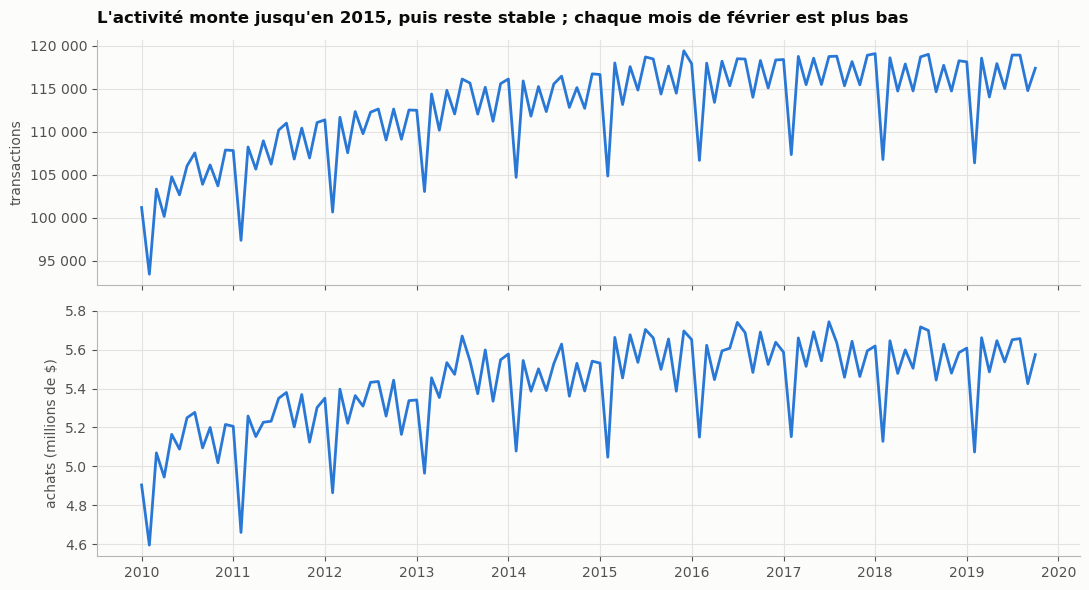

Mois le plus faible : 2010-02 93470
Mois le plus fort : 2015-12 119396
Transactions moyennes par mois de l'année :
month
1     113916
2     103135
3     114539
4     110618
5     114619
6     111852
7     115368
8     115687
9     111780
10    114864
11    111499
12    115406


In [8]:
mensuel = df.groupby(["year", "month"]).agg(transactions=("id", "size"), achats_total=("achat", "sum"))
mensuel.index = pd.to_datetime(dict(year=mensuel.index.get_level_values(0),
                                    month=mensuel.index.get_level_values(1), day=1))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(mensuel.index, mensuel["transactions"], color=BLUE)
axes[0].set_ylabel("transactions")
axes[0].yaxis.set_major_formatter(THOUSANDS)
axes[1].plot(mensuel.index, mensuel["achats_total"] / 1e6, color=BLUE)
axes[1].set_ylabel("achats (millions de $)")
axes[0].set_title("L'activité monte jusqu'en 2015, puis reste stable ; chaque mois de février est plus bas")
fig.tight_layout()
save_figure(fig, "P6-03_evolution_mensuelle")
plt.show()
print("Mois le plus faible :", mensuel["transactions"].idxmin().strftime("%Y-%m"), int(mensuel["transactions"].min()))
print("Mois le plus fort :", mensuel["transactions"].idxmax().strftime("%Y-%m"), int(mensuel["transactions"].max()))
moyenne_mois = df.groupby("month")["id"].size() / df.groupby("month")["year"].nunique()
print("Transactions moyennes par mois de l'année :")
print(moyenne_mois.round(0).astype(int).to_string())

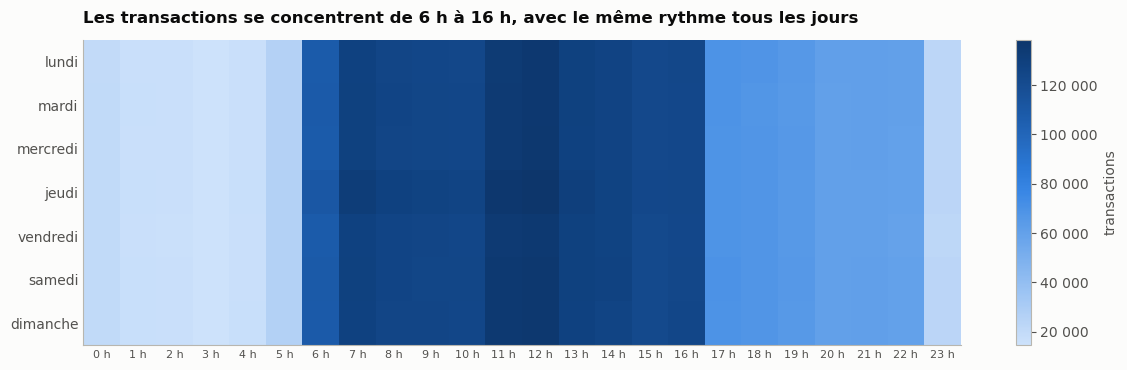

Transactions par jour :
lundi       1896914
mardi       1897678
mercredi    1895871
jeudi       1918666
vendredi    1895372
samedi      1902370
dimanche    1899044
Heure la plus chargée : 12 h (953,498) ; la plus calme : 3 h (103,478)
Part des transactions de nuit (0 h à 5 h 59) : 5.8 %


In [9]:
chaleur = df.groupby(["weekday", "hour"]).size().unstack()
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(chaleur, cmap=sequential_cmap(), aspect="auto")
ax.set_yticks(range(7))
ax.set_yticklabels(JOURS)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h} h" for h in range(24)], fontsize=8)
ax.grid(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, label="transactions", format=THOUSANDS)
ax.set_title('Les transactions se concentrent de 6 h à 16 h, avec le même rythme tous les jours')
fig.tight_layout()
save_figure(fig, "P6-03_jour_heure")
plt.show()
par_jour = df.groupby("weekday").size()
par_jour.index = JOURS
par_heure = df.groupby("hour").size()
print("Transactions par jour :")
print(par_jour.to_string())
print(f"Heure la plus chargée : {par_heure.idxmax()} h ({par_heure.max():,}) ; "
      f"la plus calme : {par_heure.idxmin()} h ({par_heure.min():,})")
print(f"Part des transactions de nuit (0 h à 5 h 59) : {100 * df['is_night'].mean():.1f} %")

**Constats**

- Le nombre de transactions monte de 1 240 880 en 2010 à 1 399 308 en 2017, puis reste stable. 2019 compte 1 159 966 transactions, car les données s'arrêtent en octobre.
- Les clients actifs passent de 1 137 en 2010 à 1 210 en 2016, et les cartes actives de 2 896 à 3 497. L'achat moyen baisse un peu, de 51,7 $ à 50,2 $.
- Le mois le plus faible est février 2010 (93 470 transactions) et le plus fort décembre 2015 (119 396). Février est chaque année le mois le plus bas (103 135 en moyenne) : il compte moins de jours.
- Le jour de la semaine ne change presque rien : de 1 895 372 transactions le vendredi à 1 918 666 le jeudi.
- L'heure compte beaucoup : la plus chargée est 12 h (953 498 transactions) et la plus calme 3 h (103 478). La carte de chaleur montre une forte activité de 6 h à 16 h, avec le même rythme tous les jours.
- 5,8 % des transactions ont lieu la nuit (de 0 h à 5 h 59).

## P6-04 : analyser la géographie (Q6)

Répartition entre achats en ligne, achats sur place aux États-Unis et achats à l'étranger, puis États et pays étrangers les plus fréquents.

Critère de fin : carte ou graphique commenté. Voir `docs/P6-04_geographie.md`.

In [10]:
lieu = np.where(df["is_online"] == 1, "En ligne", np.where(df["is_foreign"] == 1, "À l'étranger", "Sur place aux États-Unis"))
df["lieu"] = pd.Categorical(lieu)
par_lieu = df.groupby("lieu", observed=True).agg(transactions=("id", "size"), achats_total=("achat", "sum"))
par_lieu["part_transactions_%"] = 100 * par_lieu["transactions"] / len(df)
par_lieu["part_achats_%"] = 100 * par_lieu["achats_total"] / par_lieu["achats_total"].sum()
par_lieu["achat_moyen"] = df[achats].groupby("lieu", observed=True)["amount"].mean()
par_lieu.round(2)

,transactions,achats_total,part_transactions_%,part_achats_%,achat_moyen
lieu,,,,,
Sur place aux États-Unis,11653209,5.426761e+08,87.58,84.88,49.33
En ligne,1563700,9.175716e+07,11.75,14.35,59.04
À l'étranger,89006,4.921322e+06,0.67,0.77,60.69


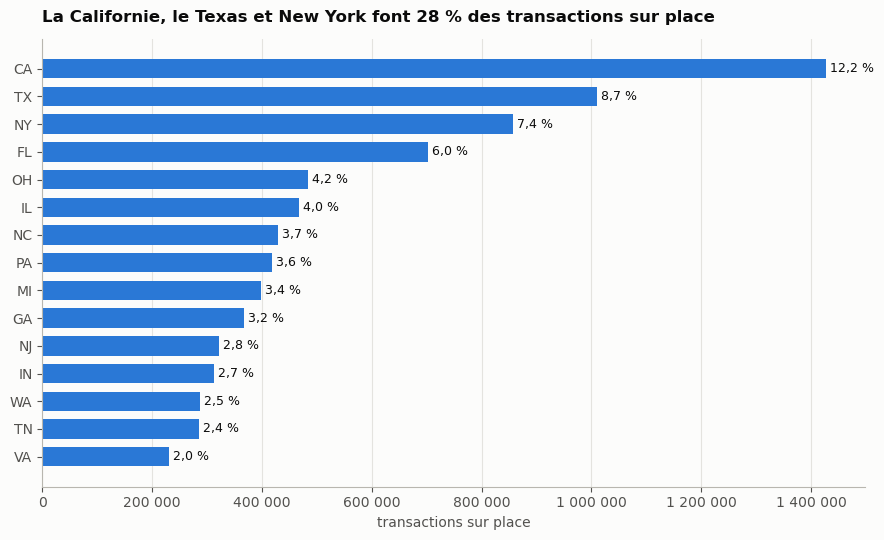

États différents : 52 ; part des 5 premiers : 38.4 %


In [11]:
sur_place = df[(df["is_online"] == 0) & (df["is_foreign"] == 0)]
etats = sur_place["merchant_state_clean"].value_counts()
etats = etats[etats > 0]
top_etats = etats.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_etats.index.astype(str), top_etats.values, color=BLUE, height=0.7)
for i, v in enumerate(top_etats.values):
    ax.text(v, i, f" {100 * v / len(sur_place):.1f} %".replace(".", ","), va="center", fontsize=9)
ax.xaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel("transactions sur place")
ax.grid(axis="y", visible=False)
ax.set_title('La Californie, le Texas et New York font 28 % des transactions sur place')
fig.tight_layout()
save_figure(fig, "P6-04_etats")
plt.show()
print(f"États différents : {len(etats)} ; part des 5 premiers : {100 * etats.head(5).sum() / len(sur_place):.1f} %")

In [12]:
pays = df.loc[df["is_foreign"] == 1, "merchant_country"].value_counts()
pays = pays[pays > 0]
print(f"Pays étrangers différents : {len(pays)} ; transactions à l'étranger : {int(pays.sum()):,}")
pays.head(10).rename("transactions")

Pays étrangers différents : 147 ; transactions à l'étranger : 89,006


Mexico            27401
Canada            10647
Italy              7081
United Kingdom     4482
Germany            3025
China              2908
France             2836
Japan              2107
Spain              1651
India              1608
Name: transactions, dtype: int64

**Constats**

- 87,58 % des transactions se font sur place aux États-Unis, 11,75 % en ligne et 0,67 % à l'étranger.
- Les achats en ligne et à l'étranger sont plus chers en moyenne (59,04 $ et 60,69 $) que les achats sur place aux États-Unis (49,33 $). Le commerce en ligne pèse donc 14,35 % du montant des achats.
- Les transactions sur place touchent 52 États. Les 5 premiers en font 38,4 % : la Californie (12,2 %), le Texas (8,7 %), New York (7,4 %), la Floride (6,0 %) et l'Ohio (4,2 %).
- 147 pays étrangers apparaissent. Le Mexique (27 401 transactions) et le Canada (10 647) dominent, devant l'Italie (7 081) et le Royaume-Uni (4 482).

## P6-05 : analyser les catégories de commerçants (Q6)

Familles (P3-05) et codes MCC les plus fréquents, en nombre et en montant, puis évolution dans le temps.

Critère de fin : graphiques commentés. Voir `docs/P6-05_categories_commercants.md`.

In [13]:
familles = df.groupby("mcc_family", observed=True).agg(transactions=("id", "size"), achats_total=("achat", "sum"))
familles["part_transactions_%"] = 100 * familles["transactions"] / familles["transactions"].sum()
familles["part_achats_%"] = 100 * familles["achats_total"] / familles["achats_total"].sum()
familles["achat_moyen"] = df[achats].groupby("mcc_family", observed=True)["amount"].mean()
familles = familles.sort_values("transactions", ascending=False)
familles.round(2)

,transactions,achats_total,part_transactions_%,part_achats_%,achat_moyen
mcc_family,,,,,
"Transport, carburant et automobile",3352312,1.313821e+08,25.19,20.55,43.08
Alimentation,3182334,7.968271e+07,23.92,12.46,27.56
Restauration et bars,1747967,4.574126e+07,13.14,7.15,26.17
Grandes surfaces et commerces divers,1332087,7.606408e+07,10.01,11.90,57.10
Santé et soins,886034,5.386477e+07,6.66,8.42,60.79
Services professionnels et financiers,718301,7.272377e+07,5.40,11.37,102.76
"Loisirs, culture et divertissement",638844,2.880114e+07,4.80,4.50,45.08
Services publics et télécommunications,626682,6.373402e+07,4.71,9.97,102.45
"Maison, jardin et électronique",352851,2.668314e+07,2.65,4.17,76.71


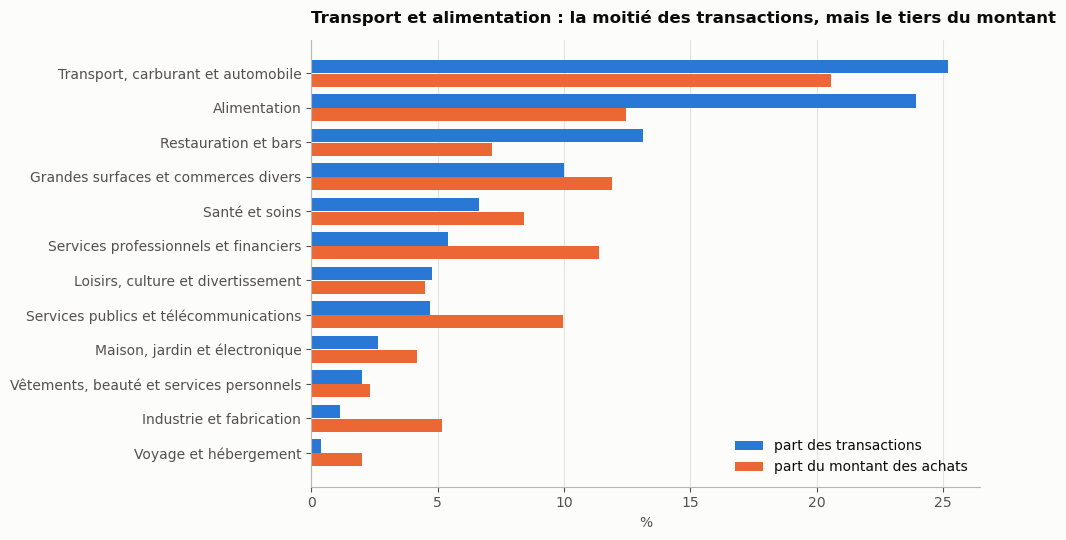

In [14]:
ordre = familles.sort_values("part_transactions_%").index
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(ordre))
ax.barh(y + 0.2, familles.loc[ordre, "part_transactions_%"], height=0.38, color=BLUE, label="part des transactions")
ax.barh(y - 0.2, familles.loc[ordre, "part_achats_%"], height=0.38, color=ORANGE, label="part du montant des achats")
ax.set_yticks(y)
ax.set_yticklabels(ordre)
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title('Transport et alimentation : la moitié des transactions, mais le tiers du montant')
fig.tight_layout()
save_figure(fig, "P6-05_familles")
plt.show()

In [15]:
codes = df.groupby("mcc").agg(transactions=("id", "size"), achats_total=("achat", "sum"))
codes = codes.join(df_mcc.set_index("mcc_code")[["description_fr", "famille"]])
print("Les 10 codes MCC les plus fréquents :")
print(codes.sort_values("transactions", ascending=False).head(10).to_string())
print()
print("Les 10 codes MCC qui pèsent le plus en montant :")
print(codes.sort_values("achats_total", ascending=False).head(10).round(0).to_string())

Les 10 codes MCC les plus fréquents :
      transactions  achats_total                        description_fr                                famille
mcc                                                                                                          
5411       1592584   40970767.06             Épiceries et supermarchés                           Alimentation
5499       1460875   37352646.05        Magasins d'alimentation divers                           Alimentation
5541       1424711   51239755.42                      Stations-service     Transport, carburant et automobile
5812        999738   26348245.60  Restaurants et lieux de restauration                   Restauration et bars
5912        772913   35113566.87                            Pharmacies                         Santé et soins
4784        674135   23859553.27               Péages et frais de pont     Transport, carburant et automobile
5300        601942   37697568.71                       Clubs-entrepôts   Grandes s

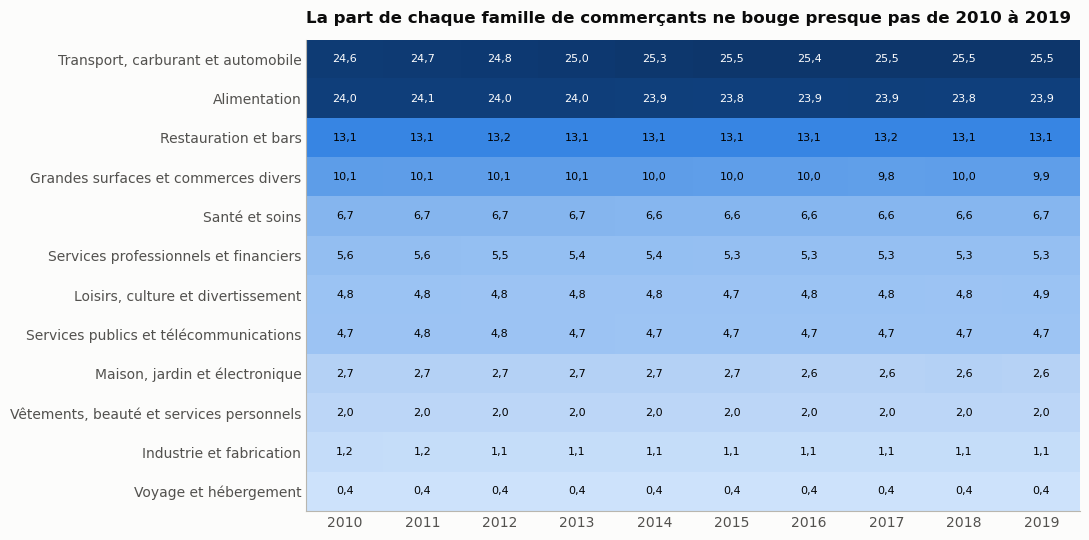

Écart entre la part la plus haute et la plus basse de 2010 à 2019 (points) :
mcc_family
Transport, carburant et automobile          0.91
Grandes surfaces et commerces divers        0.29
Services professionnels et financiers       0.27
Alimentation                                0.23
Loisirs, culture et divertissement          0.13
Maison, jardin et électronique              0.11
Industrie et fabrication                    0.11
Restauration et bars                        0.11
Santé et soins                              0.10
Services publics et télécommunications      0.09
Vêtements, beauté et services personnels    0.05
Voyage et hébergement                       0.03


In [16]:
evolution = pd.crosstab(df["mcc_family"], df["year"], normalize="columns").mul(100)
evolution = evolution.loc[familles.index]
fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(evolution, cmap=sequential_cmap(), aspect="auto")
ax.set_xticks(range(evolution.shape[1]))
ax.set_xticklabels(evolution.columns)
ax.set_yticks(range(evolution.shape[0]))
ax.set_yticklabels(evolution.index)
ax.grid(False)
ax.tick_params(length=0)
seuil = evolution.to_numpy().max() * 0.6
for i in range(evolution.shape[0]):
    for j in range(evolution.shape[1]):
        v = evolution.iloc[i, j]
        ax.text(j, i, f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=8,
                color="white" if v > seuil else "black")
ax.set_title('La part de chaque famille de commerçants ne bouge presque pas de 2010 à 2019')
fig.tight_layout()
save_figure(fig, "P6-05_familles_annees")
plt.show()
ecart = (evolution.max(axis=1) - evolution.min(axis=1)).sort_values(ascending=False)
print("Écart entre la part la plus haute et la plus basse de 2010 à 2019 (points) :")
print(ecart.round(2).to_string())

**Constats**

- Transport, carburant et automobile (25,19 % des transactions) et alimentation (23,92 %) font ensemble près de la moitié des transactions, mais seulement 20,55 % et 12,46 % du montant.
- À l'inverse, certaines familles pèsent plus en montant qu'en nombre : services professionnels et financiers (5,40 % des transactions, 11,37 % du montant), services publics et télécommunications (4,71 % et 9,97 %), industrie et fabrication (1,13 % et 5,17 %).
- Les achats les plus chers sont en voyage et hébergement (338,70 $ en moyenne) et en industrie et fabrication (306,26 $). Les moins chers sont en restauration (26,17 $) et en alimentation (27,56 $).
- Les codes les plus fréquents sont les épiceries et supermarchés (1 592 584 transactions), les magasins d'alimentation divers (1 460 875) et les stations-service (1 424 711).
- En montant, les transferts d'argent arrivent en tête (53 158 516 $), devant les stations-service (51 239 755 $).
- La part de chaque famille ne bouge presque pas de 2010 à 2019 : l'écart le plus grand est de 0,91 point (transport), et 0,29 point au plus pour les autres familles.

## P6-06 : analyser les erreurs et les refus

Taux d'erreur par canal, par famille et par heure, types d'erreur par canal, puis cartes aux erreurs répétées. Pour chaque comparaison, le tableau donne l'écart au taux global (en points et en rapport) et le test du khi-deux donne la taille de l'écart (V de Cramér).

Critère de fin : tableau et constats. Voir `docs/P6-06_erreurs_refus.md`.

In [17]:
print(f"Taux d'erreur global : {100 * df['has_error'].mean():.3f} % ; "
      f"taux d'échec d'authentification : {100 * df['has_auth_error'].mean():.3f} %")
print()
print("Par canal :")
print(rate_table(df, "canal", "has_error").to_string())
print()
print("Par famille de commerçants :")
print(rate_table(df, "mcc_family", "has_error").sort_values("taux_%", ascending=False).to_string())

Taux d'erreur global : 1.589 % ; taux d'échec d'authentification : 0.406 %

Par canal :
                  transactions     cas  taux_%  écart_points  rapport
canal                                                                
Bande magnétique       6967185  103538   1.486        -0.103     0.94
En ligne               1557912   35561   2.283         0.694     1.44
Puce                   4780818   72294   1.512        -0.077     0.95

Par famille de commerçants :
                                          transactions    cas  taux_%  écart_points  rapport
mcc_family                                                                                  
Services professionnels et financiers           718301  20559   2.862         1.273     1.80
Services publics et télécommunications          626682  14020   2.237         0.648     1.41
Voyage et hébergement                            52026   1042   2.003         0.414     1.26
Grandes surfaces et commerces divers           1332087  25825   1.9

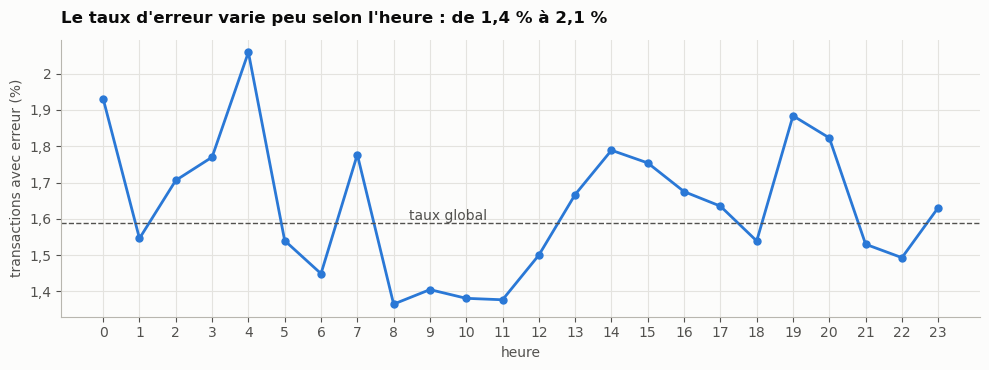

Heures au taux le plus haut :
      transactions    cas  taux_%  écart_points  rapport
hour                                                    
4           114985   2368   2.059         0.471     1.30
0           140582   2714   1.931         0.342     1.22
19          457434   8619   1.884         0.295     1.19
20          423636   7723   1.823         0.234     1.15
14          887776  15883   1.789         0.200     1.13


In [18]:
par_heure_err = rate_table(df, "hour", "has_error")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(par_heure_err.index, par_heure_err["taux_%"], marker="o", markersize=5, color=BLUE)
ax.axhline(100 * df["has_error"].mean(), color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.text(9.5, 100 * df["has_error"].mean(), "taux global", va="bottom", ha="center", color=TEXT_SECONDARY)
ax.yaxis.set_major_formatter(DECIMALS)
ax.set_xticks(range(24))
ax.set_xlabel("heure")
ax.set_ylabel("transactions avec erreur (%)")
ax.set_title("Le taux d'erreur varie peu selon l'heure : de 1,4 % à 2,1 %")
fig.tight_layout()
save_figure(fig, "P6-06_erreurs_heure")
plt.show()
print("Heures au taux le plus haut :")
print(par_heure_err.sort_values("taux_%", ascending=False).head(5).to_string())

In [19]:
types = ["err_insufficient_balance", "err_technical_glitch", "err_bad_pin", "err_bad_cvv",
         "err_bad_card_number", "err_bad_expiration", "err_bad_zipcode"]
(df.groupby("canal", observed=True)[types].mean() * 100).round(3).T

canal,Bande magnétique,En ligne,Puce
err_insufficient_balance,1.006,0.793,1.028
err_technical_glitch,0.199,0.199,0.202
err_bad_pin,0.275,0.000,0.278
err_bad_cvv,0.000,0.400,0.000
err_bad_card_number,0.000,0.509,0.000
err_bad_expiration,0.000,0.404,0.000
err_bad_zipcode,0.010,0.000,0.009


In [20]:
tests = pd.DataFrame([chi2_test(df, col, "has_error") for col in ["canal", "mcc_family", "hour", "weekday", "lieu"]])
tests

,variable,test,statistique,ddl,p_valeur,taille d'effet,mesure,lecture
0,canal,khi-deux,5446.3,2,0.000000,0.020,V de Cramér,négligeable
1,mcc_family,khi-deux,16705.3,11,0.000000,0.035,V de Cramér,négligeable
2,hour,khi-deux,2545.4,23,0.000000,0.014,V de Cramér,négligeable
3,weekday,khi-deux,5.3,6,0.504081,0.001,V de Cramér,négligeable
4,lieu,khi-deux,5336.7,2,0.000000,0.020,V de Cramér,négligeable


In [21]:
erreurs_carte = df.groupby("card_id")["has_error"].sum()
serie = (df["card_auth_errors_24h"] + df["has_auth_error"]) >= 3
cartes_serie = df.loc[serie, "card_id"].nunique()
print(f"Cartes actives : {df['card_id'].nunique():,}")
print(f"Cartes avec au moins une erreur : {int((erreurs_carte > 0).sum()):,}")
print(f"Erreurs par carte : médiane {erreurs_carte.median():.0f}, quantile 99 % {erreurs_carte.quantile(0.99):.0f}, "
      f"maximum {erreurs_carte.max()}")
print(f"Cartes qui ont eu au moins 3 échecs d'authentification en 24 heures : {cartes_serie:,}")
print(f"Transactions concernées (3e échec ou plus en 24 heures) : {int(serie.sum()):,}")

Cartes actives : 4,071
Cartes avec au moins une erreur : 4,017
Erreurs par carte : médiane 36, quantile 99 % 286, maximum 1226
Cartes qui ont eu au moins 3 échecs d'authentification en 24 heures : 12
Transactions concernées (3e échec ou plus en 24 heures) : 34


**Constats**

- 1,589 % des transactions ont une erreur et 0,406 % un échec d'authentification.
- Le taux d'erreur est plus haut en ligne (2,283 %, soit 1,44 fois le taux global) que par puce (1,512 %) ou par bande magnétique (1,486 %).
- Par famille, il va de 1,012 % en restauration (0,64 fois le taux global) à 2,862 % en services professionnels et financiers (1,80 fois).
- Par heure, il va d'environ 1,4 % (de 8 h à 11 h) à 2,059 % (4 h).
- Les types d'erreur dépendent du canal : les erreurs de CVV (0,400 %), de numéro (0,509 %) et d'expiration (0,404 %) n'existent qu'en ligne, et les erreurs de PIN (environ 0,28 %) qu'avec une carte physique. Le solde insuffisant (environ 1 %) et la panne technique (environ 0,2 %) touchent tous les canaux.
- Tous les tests du khi-deux sont significatifs, sauf pour le jour de la semaine (p = 0,504). Mais les V de Cramér vont de 0,001 à 0,035 : les écarts sont réels, mais négligeables en taille.
- 4 017 des 4 071 cartes actives ont eu au moins une erreur. Une carte en compte 36 en médiane, 286 au quantile 99 % et 1 226 au maximum.
- 12 cartes ont eu au moins 3 échecs d'authentification en 24 heures, pour 34 transactions concernées.

## P6-07 : croiser comportements et profils de clients

Comportements de chaque profil de la phase 5 (`data/clean/client_profiles.parquet`).

Critère de fin : tableau comparatif des profils. Voir `docs/P6-07_comportements_profils.md`.

In [22]:
profils = load_clean_table("client_profiles", columns=["client_id", "profil", "profil_nom"])
df["profil_nom"] = df["client_id"].map(profils.set_index("client_id")["profil_nom"]).astype("category")

comparatif = df.groupby("profil_nom", observed=True).agg(
    clients=("client_id", "nunique"),
    transactions=("id", "size"),
    part_en_ligne=("is_online", "mean"),
    part_etranger=("is_foreign", "mean"),
    part_nuit=("is_night", "mean"),
    part_week_end=("is_weekend", "mean"),
    taux_erreur=("has_error", "mean"),
    part_remboursements=("is_negative_amount", "mean"),
)
for col in ["part_en_ligne", "part_etranger", "part_nuit", "part_week_end", "taux_erreur", "part_remboursements"]:
    comparatif[col] = (100 * comparatif[col]).round(2)
comparatif["achat_median"] = df[achats].groupby("profil_nom", observed=True)["amount"].median()
comparatif["transactions_par_client"] = (comparatif["transactions"] / comparatif["clients"]).round(0)
famille_principale = (df.groupby(["profil_nom", "mcc_family"], observed=True).size()
                      .groupby(level=0, group_keys=False, observed=True).nlargest(1).reset_index(level=1)["mcc_family"])
comparatif["famille_principale"] = famille_principale
comparatif.T

profil_nom,Clients aisés et voyageurs,Clients courants,Acheteurs en ligne très actifs,Clients sans dette,Revenu suspect (non classé)
clients,321,686,138,63,11
transactions,3670782,6530116,2319470,711056,74491
part_en_ligne,8.12,5.9,35.12,8.65,5.47
part_etranger,1.32,0.4,0.44,0.53,0.06
part_nuit,5.79,5.56,6.48,5.95,3.37
part_week_end,28.55,28.58,28.56,28.58,28.54
taux_erreur,1.55,1.63,1.6,1.47,0.59
part_remboursements,5.65,4.96,4.18,4.2,3.06
achat_median,45.13,28.25,30.12,27.79,9.07
transactions_par_client,11435.0,9519.0,16808.0,11287.0,6772.0


In [23]:
pd.DataFrame([{**chi2_test(df.dropna(subset=["profil_nom"]), "profil_nom", col), "variable": f"profil et {col}"}
              for col in ["is_online", "is_foreign", "is_night", "has_error"]])

,variable,test,statistique,ddl,p_valeur,taille d'effet,mesure,lecture
0,profil et is_online,khi-deux,1492801.2,4,0.000000e+00,0.335,V de Cramér,moyen
1,profil et is_foreign,khi-deux,33026.5,4,0.000000e+00,0.050,V de Cramér,négligeable
2,profil et is_night,khi-deux,3518.1,4,0.000000e+00,0.016,V de Cramér,négligeable
3,profil et has_error,khi-deux,646.9,4,1.097877e-138,0.007,V de Cramér,négligeable


**Constats**

- Les acheteurs en ligne très actifs font 35,12 % de leurs transactions en ligne, contre 5,9 % à 8,65 % pour les trois autres profils. Ils comptent aussi le plus de transactions par client (16 808). Leur famille principale est le transport ; pour tous les autres profils, c'est l'alimentation.
- Les clients aisés et voyageurs achètent le plus à l'étranger (1,32 % de leurs transactions, contre 0,40 % à 0,53 % pour les trois autres profils). Ils ont l'achat médian le plus élevé (45,13 $) et le plus de remboursements (5,65 %).
- Les autres comportements varient peu entre les profils : nuit de 5,56 % à 6,48 %, week-end de 28,55 % à 28,58 %, taux d'erreur de 1,47 % à 1,63 %.
- Le lien entre profil et achat en ligne est de taille moyenne (V de Cramér de 0,335). Les liens avec l'étranger (0,050), la nuit (0,016) et les erreurs (0,007) sont négligeables.

## P6-08 : visuels clés des comportements (Q2, Q6)

Les visuels de cette phase sont enregistrés dans `docs/figures/`. Chacun annonce son message dans son titre et suit la charte (`src/charte.py`) :

- `P6-01_montants.png` : distribution des montants ;
- `P6-02_canaux_paiement.png` : canaux de paiement par année ;
- `P6-03_evolution_mensuelle.png` : courbe mensuelle ;
- `P6-03_jour_heure.png` : carte de chaleur jour et heure ;
- `P6-04_etats.png` : États les plus fréquents ;
- `P6-05_familles.png` et `P6-05_familles_annees.png` : familles de commerçants ;
- `P6-06_erreurs_heure.png` : taux d'erreur par heure.

Critère de fin : visuels relus par un autre membre. Voir `docs/P6-08_visuels_comportements.md`.